# ML Assignment 2: Stroke Prediction Classification
This notebook implements 5 classification models to predict the likelihood of stroke based on healthcare data.

## 1. Imports and Data Loading

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef, confusion_matrix, classification_report
import joblib

# Load dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Exploratory Data Analysis (EDA)
Understanding the distribution of the target variable and features.

Missing values per column: id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


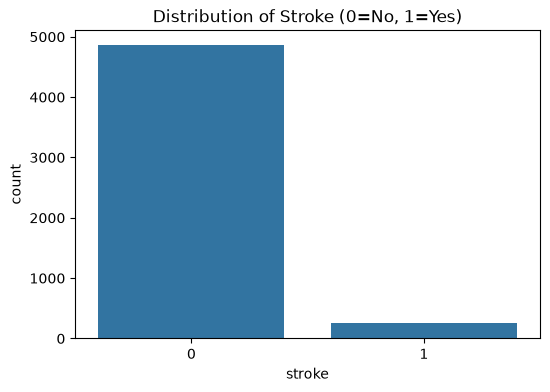

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [14]:
# Check for missing values
print("Missing values per column:", df.isnull().sum())

# Plot target distribution
plt.figure(figsize=(6,4))
sns.countplot(x='stroke', data=df)
plt.title('Distribution of Stroke (0=No, 1=Yes)')
plt.show()

# Basic stats
df.describe()

## 3. Data Preprocessing
Handling missing values, encoding categories, and scaling numerical data.

In [15]:
# Drop ID column
df = df.drop('id', axis=1)

# 1. Handle Missing Values
# BMI has 'N/A' strings or NaNs. Convert to numeric first.
df['bmi'] = pd.to_numeric(df['bmi'], errors='coerce')
imputer = SimpleImputer(strategy='median')
df['bmi'] = imputer.fit_transform(df[['bmi']])

# 2. Encode Categorical Variables
label_encoders = {}
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# 3. Split Data
X = df.drop('stroke', axis=1)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing complete. Training set shape:", X_train_scaled.shape)

Preprocessing complete. Training set shape: (4088, 10)


## 4. Model Implementation and Evaluation
We will implement 5 models and evaluate them using the required 6 metrics.

In [16]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced'),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC(probability=True, class_weight='balanced')
}

results = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predict
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Metrics
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }
    results[name] = metrics
    
    # Save model
    joblib.dump(model, f'model/{name.lower().replace(" ", "_")}_model.pkl')
    print(f"{name} trained and saved.")

# Convert results to DataFrame
results_df = pd.DataFrame(results).T
results_df

Logistic Regression trained and saved.
Decision Tree trained and saved.
KNN trained and saved.
Naive Bayes trained and saved.


c:\Users\Karthik Sivaram\Desktop\Bits_Projects\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained and saved.


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.751468,0.838704,0.140845,0.80,0.239521,0.264351
Decision Tree,0.927593,0.525597,0.125000,0.08,0.097561,0.063407
KNN,0.948141,0.613961,0.200000,0.02,0.036364,0.049108
Naive Bayes,0.867906,0.803272,0.165354,0.42,0.237288,0.203325
SVM,0.735812,0.785617,0.118056,0.68,0.201183,0.200752


## 5. Final Analysis
Comparison table and observations.

Comparison Table:


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.751468,0.838704,0.140845,0.80,0.239521,0.264351
Decision Tree,0.927593,0.525597,0.125000,0.08,0.097561,0.063407
KNN,0.948141,0.613961,0.200000,0.02,0.036364,0.049108
Naive Bayes,0.867906,0.803272,0.165354,0.42,0.237288,0.203325
SVM,0.735812,0.785617,0.118056,0.68,0.201183,0.200752


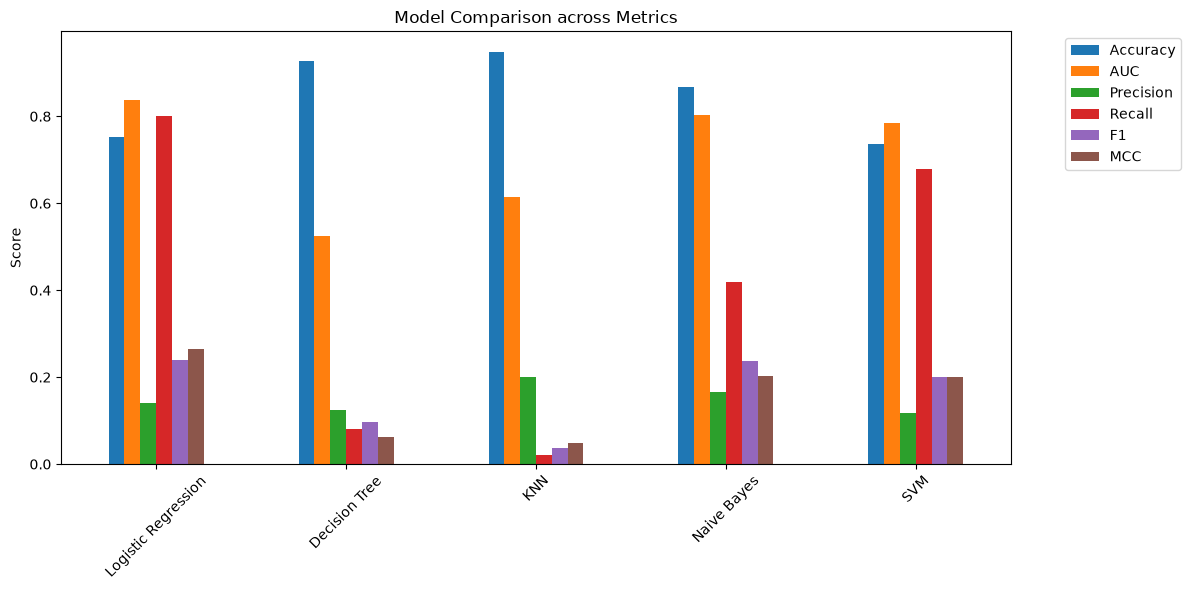

In [17]:
# Final Comparison Table
print("Comparison Table:")
display(results_df)

# Visualization of metrics
results_df.plot(kind='bar', figsize=(12,6))
plt.title('Model Comparison across Metrics')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Save Preprocessing Artifacts
Saving the scaler for use in the Streamlit app.

In [18]:
# Save the scaler
joblib.dump(scaler, 'model/scaler.pkl')

# Save all label encoders as a dictionary
joblib.dump(label_encoders, 'model/label_encoders.pkl')

# Save the imputer for consistency during prediction
joblib.dump(imputer, 'model/imputer.pkl')

print("Scaler, Label Encoders, and Imputer saved successfully!")

Scaler, Label Encoders, and Imputer saved successfully!
